# Credit Card Default Data Analysis
## Foundations of Data Science — Lab Evaluation 1

**Dataset:** Default of Credit Card Clients Dataset  
**Source:** UCI Machine Learning Repository  
**File:** `default of credit card clients.xls`  

---

## 1. Problem Statement

### 1.1 Background
Credit cards are one of the most common financial products offered by retail banks. When a bank issues a credit card to a customer, it grants them a revolving line of credit. The customer can borrow money up to an agreed limit to make purchases, and each month they receive a bill statement showing their balance. The customer can choose to pay the full balance, pay a minimum amount, or carry the balance forward to the next month with interest.

Banks earn money through interest charges and transaction merchant fees. However, the biggest financial risk to any credit card issuer is **default** — when a customer repeatedly fails to make the required minimum payments and eventually cannot repay their debt.

### 1.2 The Problem
In this dataset, out of 30,000 credit card clients from a major retail bank in Taiwan, **6,636 customers (22.12%) defaulted on their payment next month**, while **23,364 customers (77.88%) paid successfully**.

In other words, roughly **1 out of every 5 customers defaulted**. When a customer defaults, the bank loses the outstanding borrowed money, incurs legal and collection costs, and faces capital reserve pressure. The bank needs to understand customer payment behaviors and demographic factors associated with default so it can set responsible credit limits and flag at-risk accounts early.

### 1.3 Analytical Objective
Using the customer information, billing statements, and past repayment history the bank already holds, identify which customer characteristics and payment patterns are associated with a customer defaulting on their payment — so that credit monitoring can focus on higher-risk accounts.

This is framed as a **statistical analysis, not a complex machine learning prediction model**. No black-box classifier is trained. The goal is to measure, explain, and visualize the patterns in the data, and to state how confident we can be in those patterns using probability and sampling theory.

### 1.4 Specific Goals
1. Describe the customer population holding credit cards in the dataset.
2. Compare defaulters with non-defaulters and quantify how they differ.
3. Determine which past payment status months and billing patterns are most strongly linked to default.
4. Express customers mathematically as feature vectors and study how their attributes move together using covariance and correlation matrices.
5. Model the default outcome using appropriate probability distributions (Bernoulli and Binomial).
6. Use sampling and the Central Limit Theorem (CLT) to establish how reliable the estimated default rate and customer metrics are.

### 1.5 Target Variable
The target variable is `y` (renamed from `default payment next month`):

| Value | Meaning | Count | Share |
|---|---|---|---|
| **0 (no)** | Did not default (paid successfully) | 23,364 | 77.88% |
| **1 (yes)** | Defaulted on next month's payment | 6,636 | 22.12% |

The target `y` is a binary categorical variable. Because the two classes are unequal (about 3.5 : 1), overall accuracy alone can be misleading. Every analytical result in this notebook is therefore compared against the **22.12% baseline default rate**, not against 50%.

---

## 2. Dataset Description

### 2.1 Source
- **Name:** Default of Credit Card Clients Dataset
- **Source:** UCI Machine Learning Repository (DOI: 10.24432/C55S3H)
- **Origin:** Real, anonymised operational records from a Taiwanese credit card issuer
- **Period Covered:** April 2005 – September 2005 (6-month panel data)
- **File Used:** `default of credit card clients.xls`
- **Size:** 30,000 rows × 24 columns (plus target)
- **Row Meaning:** One credit card customer's financial account profile

### 2.2 Structure of the Columns
The columns fall into four natural functional groups plus the target:

**Group A — Customer Demographics (5 columns)**
- `LIMIT_BAL`: Amount of given credit (in New Taiwan Dollars, NT$)
- `SEX`: Gender (1 = male, 2 = female)
- `EDUCATION`: Education level (1 = graduate school, 2 = university, 3 = high school, 4 = others)
- `MARRIAGE`: Marital status (1 = married, 2 = single, 3 = others)
- `AGE`: Age of the customer in years

**Group B — Past Repayment Status (6 columns)**
- `PAY_0` to `PAY_6`: Repayment status from September 2005 (`PAY_0`) back to April 2005 (`PAY_6`). Values: -1 = pay duly, 1 = payment delay for one month, 2 = payment delay for two months, up to 9 = delay for nine months or more.

**Group C — Monthly Bill Statements (6 columns)**
- `BILL_AMT1` to `BILL_AMT6`: Amount of bill statement in NT$ from September 2005 (`BILL_AMT1`) back to April 2005 (`BILL_AMT6`).

**Group D — Previous Payment Amounts (6 columns)**
- `PAY_AMT1` to `PAY_AMT6`: Amount of previous payment in NT$ made in September 2005 (`PAY_AMT1`) back to April 2005 (`PAY_AMT6`).

**Target Variable**
- `y`: Default payment next month (1 = default / yes, 0 = non-default / no)

### 2.3 Known Data Quality Issues
1. **Undocumented Category Codes:** The original data contains undocumented codes in `EDUCATION` (0, 5, 6) and `MARRIAGE` (0). These are cleaned and merged into category 4 ("Others") and 3 ("Others") respectively.
2. **Duplicate Records:** Duplicate check is performed to verify data uniqueness.
3. **Negative Bill Amounts:** Some billing statement amounts are negative, which in retail banking represents credit balances, overpayments, or merchant refunds.

### 2.4 Why this Dataset Suits the Analysis
| Requirement | How this Dataset Supports It |
|---|---|
| **Preprocessing** | Categorical cleaning, duplicate check, scaling, encoding, discretization |
| **Vector / Matrix Work** | Continuous financial columns create customer feature vectors and a $30,000 \times 4$ real matrix |
| **EDA** | Multiple demographic and billing columns to group and compare against the target |
| **Probability** | Clean binary outcome for Bernoulli and Binomial probability models |
| **Sampling / CLT** | 30,000 rows, large enough to treat as a true population and draw repeated samples from |


---
## 2. Understanding the Dataset
This section imports the core libraries, loads the dataset, and identifies the dataset structure, features, data types, and target variable.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visualization theme
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.figsize': (8, 5)})

# Load dataset (header is at row index 1 in the original excel file)
file_name = 'default of credit card clients.xls'
alt_path = os.path.join('default_card', file_name)

if os.path.exists(file_name):
    df = pd.read_excel(file_name, header=1)
elif os.path.exists(alt_path):
    df = pd.read_excel(alt_path, header=1)
else:
    raise FileNotFoundError(f"Dataset file '{file_name}' not found.")

print("✅ Dataset loaded successfully.")


✅ Dataset loaded successfully.


In [2]:
print(df.head())


   ID  LIMIT_BAL  SEX  ...  PAY_AMT5  PAY_AMT6  default payment next month
0   1      20000    2  ...         0         0                           1
1   2     120000    2  ...         0      2000                           1
2   3      90000    2  ...      1000      5000                           0
3   4      50000    2  ...      1069      1000                           0
4   5      50000    1  ...       689       679                           0

[5 rows x 25 columns]


In [3]:
print("Dataset Shape (rows, columns):", df.shape)


Dataset Shape (rows, columns): (30000, 25)


In [4]:
print("Columns in dataset:")
print(df.columns.tolist())


Columns in dataset:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


In [5]:
print("Data types of columns:")
print(df.dtypes)


Data types of columns:
ID                            int64
LIMIT_BAL                     int64
SEX                           int64
EDUCATION                     int64
MARRIAGE                      int64
AGE                           int64
PAY_0                         int64
PAY_2                         int64
PAY_3                         int64
PAY_4                         int64
PAY_5                         int64
PAY_6                         int64
BILL_AMT1                     int64
BILL_AMT2                     int64
BILL_AMT3                     int64
BILL_AMT4                     int64
BILL_AMT5                     int64
BILL_AMT6                     int64
PAY_AMT1                      int64
PAY_AMT2                      int64
PAY_AMT3                      int64
PAY_AMT4                      int64
PAY_AMT5                      int64
PAY_AMT6                      int64
default payment next month    int64
dtype: object


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

In [7]:
print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64


In [8]:
print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


In [9]:
print(df.describe().round(2))


             ID   LIMIT_BAL  ...   PAY_AMT6  default payment next month
count  30000.00    30000.00  ...   30000.00                    30000.00
mean   15000.50   167484.32  ...    5215.50                        0.22
std     8660.40   129747.66  ...   17777.47                        0.42
min        1.00    10000.00  ...       0.00                        0.00
25%     7500.75    50000.00  ...     117.75                        0.00
50%    15000.50   140000.00  ...    1500.00                        0.00
75%    22500.25   240000.00  ...    4000.00                        0.00
max    30000.00  1000000.00  ...  528666.00                        1.00

[8 rows x 25 columns]


In [10]:
numeric_columns = df.select_dtypes(include=['number']).columns
categorical_columns = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

print("Numerical columns:")
print(list(numeric_columns))

print("\nCategorical columns:")
print(categorical_columns)


Numerical columns:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Categorical columns:
['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']


In [11]:
feature_description = {
    'ID': 'Unique client ID index',
    'LIMIT_BAL': 'Amount of given credit in NT$',
    'SEX': 'Gender (1=Male, 2=Female)',
    'EDUCATION': 'Education level (1=Grad school, 2=University, 3=High school, 4=Others)',
    'MARRIAGE': 'Marital status (1=Married, 2=Single, 3=Others)',
    'AGE': 'Age in years',
    'PAY_0': 'Repayment status in September 2005',
    'PAY_2': 'Repayment status in August 2005',
    'PAY_3': 'Repayment status in July 2005',
    'PAY_4': 'Repayment status in June 2005',
    'PAY_5': 'Repayment status in May 2005',
    'PAY_6': 'Repayment status in April 2005',
    'BILL_AMT1': 'Bill statement amount in September 2005 (NT$)',
    'BILL_AMT2': 'Bill statement amount in August 2005 (NT$)',
    'BILL_AMT3': 'Bill statement amount in July 2005 (NT$)',
    'BILL_AMT4': 'Bill statement amount in June 2005 (NT$)',
    'BILL_AMT5': 'Bill statement amount in May 2005 (NT$)',
    'BILL_AMT6': 'Bill statement amount in April 2005 (NT$)',
    'PAY_AMT1': 'Amount paid in September 2005 (NT$)',
    'PAY_AMT2': 'Amount paid in August 2005 (NT$)',
    'PAY_AMT3': 'Amount paid in July 2005 (NT$)',
    'PAY_AMT4': 'Amount paid in June 2005 (NT$)',
    'PAY_AMT5': 'Amount paid in May 2005 (NT$)',
    'PAY_AMT6': 'Amount paid in April 2005 (NT$)',
    'default payment next month': 'Target: Whether customer defaulted (1=Yes, 0=No)'
}

feature_table = pd.DataFrame({
    'Feature': df.columns,
    'Description': [feature_description.get(col, '') for col in df.columns],
    'Data Type': [str(df[col].dtype) for col in df.columns]
})

print(feature_table.to_string(index=False))


                   Feature                                                            Description Data Type
                        ID                                                 Unique client ID index     int64
                 LIMIT_BAL                                          Amount of given credit in NT$     int64
                       SEX                                              Gender (1=Male, 2=Female)     int64
                 EDUCATION Education level (1=Grad school, 2=University, 3=High school, 4=Others)     int64
                  MARRIAGE                         Marital status (1=Married, 2=Single, 3=Others)     int64
                       AGE                                                           Age in years     int64
                     PAY_0                                     Repayment status in September 2005     int64
                     PAY_2                                        Repayment status in August 2005     int64
                     PAY_3  

In [12]:
# Target Variable Distribution
target_col = 'default payment next month'
print("Target Variable Counts:")
print(df[target_col].value_counts())

print("\nTarget Variable Percentage:")
print((df[target_col].value_counts(normalize=True) * 100).round(2))


Target Variable Counts:
default payment next month
0    23364
1     6636
Name: count, dtype: int64

Target Variable Percentage:
default payment next month
0    77.88
1    22.12
Name: proportion, dtype: float64


---
## 3. Analysis Questions
The following 15 meaningful questions are framed for the Credit Card Default dataset.

1. **Q1.** What are the general demographic characteristics (age, education, marital status) of credit card holders in the dataset?
2. **Q2.** Is the customer population heterogeneous, or are there distinct customer segments with different characteristics?
3. **Q3.** Which characteristics distinguish customers who defaulted from those who did not?
4. **Q4.** Which past payment status variables show the strongest relationship with the default outcome?
5. **Q5.** Does repeated payment delay increase the chance of default, or does risk level remain constant?
6. **Q6.** How can each customer be represented as a multidimensional feature vector, and how does the average customer vector differ between defaulters and non-defaulters?
7. **Q7.** Which customer financial attributes exhibit the strongest covariance and correlation, and what do these relationships reveal?
8. **Q8.** How different are individual customers from the average customer in multidimensional feature space (Euclidean distance)?
9. **Q9.** Are default outcomes and customer attributes statistically independent, or are they related?
10. **Q10.** How does the probability of default change when customer and financial characteristics are conditioned on?
11. **Q11.** Can the number of defaulters in a random group of 10 customers be modeled using a Binomial distribution?
12. **Q12.** How accurately can the overall default rate be estimated from a random sample of customers, and how many customers must be sampled to reach a target precision?
13. **Q13.** How does increasing sample size affect the variability of the estimated default rate?
14. **Q14.** Does the sampling distribution of mean credit limits approach a normal distribution as sample size increases (Central Limit Theorem)?
15. **Q15.** What combination of customer characteristics and payment history provides the clearest indication of default risk, and how reliable are these findings under random sampling?


---
## 4. Data Preprocessing
Missing values, duplicate rows, categorical anomalies, encoding, scaling, dimensionality reduction, and discretization are handled here.


In [13]:
df_clean = df.copy()

# Drop arbitrary ID column if present
if 'ID' in df_clean.columns:
    df_clean.drop(columns=['ID'], inplace=True)

# Rename target column to 'y' for clarity
df_clean.rename(columns={'default payment next month': 'y'}, inplace=True)
print("Shape after dropping ID and renaming target:", df_clean.shape)


Shape after dropping ID and renaming target: (30000, 24)


In [14]:
# Check missing values
print("Missing values in df_clean:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
if df_clean.isnull().sum().sum() == 0:
    print("✅ No missing values detected in the dataset.")


Missing values in df_clean:
Series([], dtype: int64)
✅ No missing values detected in the dataset.


In [15]:
# Handling duplicates
duplicates_before = df_clean.duplicated().sum()
print("Duplicate rows before removal:", duplicates_before)

df_clean = df_clean.drop_duplicates()
duplicates_after = df_clean.duplicated().sum()
print("Duplicate rows after removal:", duplicates_after)
print("Rows remaining:", len(df_clean))


Duplicate rows before removal: 35
Duplicate rows after removal: 0
Rows remaining: 29965


In [16]:
# Clean undocumented category codes in EDUCATION and MARRIAGE
# In EDUCATION: 0, 5, 6 are undocumented -> map to 4 (Others)
df_clean['EDUCATION'] = df_clean['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

# In MARRIAGE: 0 is undocumented -> map to 3 (Others)
df_clean['MARRIAGE'] = df_clean['MARRIAGE'].replace({0: 3})

print("Cleaned EDUCATION categories:", df_clean['EDUCATION'].value_counts().sort_index().to_dict())
print("Cleaned MARRIAGE categories :", df_clean['MARRIAGE'].value_counts().sort_index().to_dict())


Cleaned EDUCATION categories: {1: 10563, 2: 14019, 3: 4915, 4: 468}
Cleaned MARRIAGE categories : {1: 13643, 2: 15945, 3: 377}


In [17]:
# Create an indicator column for whether the customer had a delayed payment in September
df_clean['has_delayed_payment'] = (df_clean['PAY_0'] > 0).astype(int)
print("Delayed payment indicator distribution:")
print(df_clean['has_delayed_payment'].value_counts())


Delayed payment indicator distribution:
has_delayed_payment
0    23169
1     6796
Name: count, dtype: int64


In [18]:
# Encoding: Create readable labels for demographic plots
edu_map = {1: 'Grad School', 2: 'University', 3: 'High School', 4: 'Others'}
mar_map = {1: 'Married', 2: 'Single', 3: 'Others'}
sex_map = {1: 'Male', 2: 'Female'}

df_clean['EDUCATION_LABEL'] = df_clean['EDUCATION'].map(edu_map)
df_clean['MARRIAGE_LABEL']  = df_clean['MARRIAGE'].map(mar_map)
df_clean['SEX_LABEL']       = df_clean['SEX'].map(sex_map)

print(df_clean[['SEX_LABEL', 'EDUCATION_LABEL', 'MARRIAGE_LABEL']].head())


  SEX_LABEL EDUCATION_LABEL MARRIAGE_LABEL
0    Female      University        Married
1    Female      University         Single
2    Female      University         Single
3    Female      University        Married
4      Male      University        Married


In [19]:
# Scaling numerical features
from sklearn.preprocessing import StandardScaler

scale_features = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 
                  'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 
                  'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

scaler = StandardScaler()
df_scaled = df_clean.copy()
df_scaled[scale_features] = scaler.fit_transform(df_clean[scale_features])
print("✅ Numerical features standardized to mean=0, std=1.")


✅ Numerical features standardized to mean=0, std=1.


Explained Variance Ratio per Principal Component:
PC1: 0.4228
PC2: 0.1226
PC3: 0.0746
PC4: 0.0661
PC5: 0.0631
PC6: 0.0623
PC7: 0.0557
PC8: 0.0519
PC9: 0.0505
PC10: 0.0189
PC11: 0.0051
PC12: 0.0029
PC13: 0.0018
PC14: 0.0017

Cumulative Explained Variance:
PC1: 0.4228
PC2: 0.5454
PC3: 0.6200
PC4: 0.6861
PC5: 0.7492
PC6: 0.8115
PC7: 0.8672
PC8: 0.9191
PC9: 0.9696
PC10: 0.9885
PC11: 0.9936
PC12: 0.9965
PC13: 0.9983
PC14: 1.0000


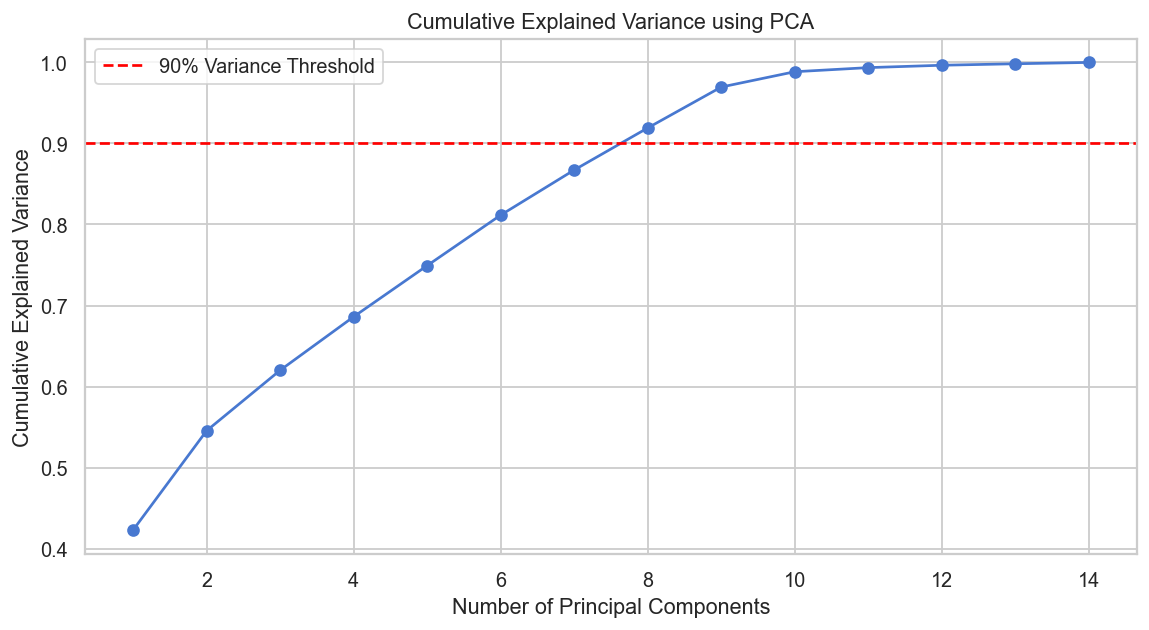

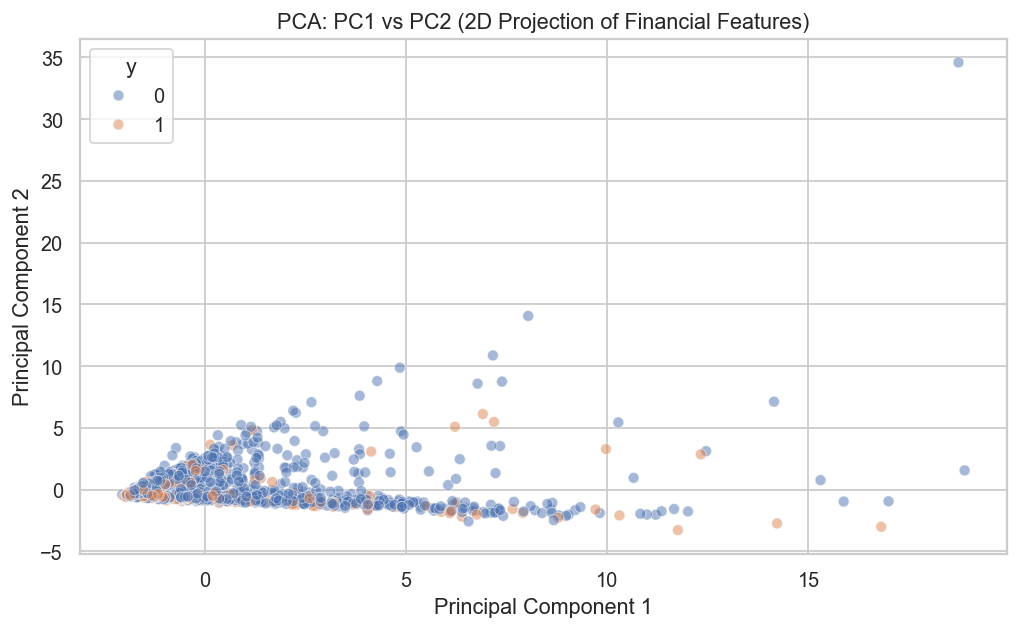

In [20]:
# Dimensionality Reduction (PCA)
from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(df_scaled[scale_features])

explained_variance = pca.explained_variance_ratio_
print("Explained Variance Ratio per Principal Component:")
for i, var in enumerate(explained_variance):
    print(f"PC{i+1}: {var:.4f}")

cumulative_variance = np.cumsum(explained_variance)
print("\nCumulative Explained Variance:")
for i, var in enumerate(cumulative_variance):
    print(f"PC{i+1}: {var:.4f}")

# Plot cumulative explained variance
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.axhline(0.90, color='red', linestyle='--', label='90% Variance Threshold')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance using PCA')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 2D PCA Scatter plot
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(df_scaled[scale_features])
pca_df = pd.DataFrame(X_2d, columns=['PC1', 'PC2'])
pca_df['y'] = df_clean['y'].values

plt.figure(figsize=(8, 5))
sns.scatterplot(data=pca_df.sample(2000, random_state=42), x='PC1', y='PC2', hue='y', alpha=0.5, palette=['#4C72B0', '#DD8452'])
plt.title('PCA: PC1 vs PC2 (2D Projection of Financial Features)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.tight_layout()
plt.show()


In [21]:
# Discretization: Binning age into standard demographic groups
df_clean['age_group'] = pd.cut(
    df_clean['AGE'],
    bins=[0, 25, 40, 60, 100],
    labels=['Young', 'Adult', 'Middle-aged', 'Senior']
)

print("Age Group Distribution:")
print(df_clean['age_group'].value_counts())

print("\nCleaned Data Summary:")
print("Rows    :", df_clean.shape[0])
print("Columns :", df_clean.shape[1])


Age Group Distribution:
age_group
Adult          17831
Middle-aged     7994
Young           3868
Senior           272
Name: count, dtype: int64

Cleaned Data Summary:
Rows    : 29965
Columns : 29


---
## 5. Vector and Matrix Concepts

### 5.1 Customer Feature Vector
**Why we need it:** A customer can be represented as a mathematical vector so that their numerical characteristics can be analyzed using linear algebra.


In [22]:
# Select important numerical features
vector_features = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']

# Represent the first customer as a vector
customer_vector = df_clean[vector_features].iloc[0].to_numpy()

print("Customer vector:")
print(customer_vector)
print("Number of features:", len(customer_vector))


Customer vector:
[20000    24  3913     0]
Number of features: 4


### 5.2 Vector Addition and Subtraction
**Why we need it:** Comparing average vectors helps us see how the numerical profiles of defaulters and non-defaulters differ across features.


In [23]:
# Find the average vector for defaulters and non-defaulters
yes_vector = df_clean[df_clean['y'] == 1][vector_features].mean().to_numpy()
no_vector  = df_clean[df_clean['y'] == 0][vector_features].mean().to_numpy()

# Subtract the two vectors
difference_vector = yes_vector - no_vector

print("Average vector - Defaulters (y=1):")
print(np.round(yes_vector, 2))

print("\nAverage vector - Non-Defaulters (y=0):")
print(np.round(no_vector, 2))

print("\nDifference vector (Defaulters - Non-Defaulters):")
print(np.round(difference_vector, 2))


Average vector - Defaulters (y=1):
[1.2998457e+05 3.5720000e+01 4.8552810e+04 3.4001200e+03]

Average vector - Non-Defaulters (y=0):
[1.7808451e+05 3.5420000e+01 5.2058720e+04 6.3150500e+03]

Difference vector (Defaulters - Non-Defaulters):
[-4.809994e+04  3.000000e-01 -3.505910e+03 -2.914930e+03]


### 5.3 Vector Magnitude
**Why we need it:** Vector magnitude gives a single overall number representing the size or distance of a customer's feature vector from the origin.


In [24]:
# Calculate the magnitude of the first customer vector
magnitude = np.linalg.norm(customer_vector)

print("Customer vector:", customer_vector)
print("Vector magnitude:", round(magnitude, 2))


Customer vector: [20000    24  3913     0]
Vector magnitude: 20379.21


### 5.4 Euclidean Distance
**Why we need it:** Distance tells us how far an individual customer's numerical profile is from the average customer profile.


In [25]:
# Calculate the average customer vector
mean_vector = df_clean[vector_features].mean().to_numpy()

# Select one customer
customer = df_clean[vector_features].iloc[0].to_numpy()

# Calculate Euclidean distance from the average customer
distance = np.linalg.norm(customer - mean_vector)

print("Average customer vector:")
print(np.round(mean_vector, 2))

print("\nCustomer vector:")
print(np.round(customer, 2))

print("\nDistance from average customer:", round(distance, 2))


Average customer vector:
[1.6744201e+05 3.5490000e+01 5.1283010e+04 5.6701000e+03]

Customer vector:
[20000    24  3913     0]

Distance from average customer: 154968.43


### 5.5 Dot Product
**Why we need it:** The dot product provides a simple measure of how two customer feature vectors interact numerically and align in direction.


In [26]:
# Select two customer vectors
vector_1 = df_clean[vector_features].iloc[0].to_numpy()
vector_2 = df_clean[vector_features].iloc[1].to_numpy()

# Calculate the dot product
dot_product = np.dot(vector_1, vector_2)

print("Vector 1:", vector_1)
print("Vector 2:", vector_2)
print("Dot product:", dot_product)


Vector 1: [20000    24  3913     0]
Vector 2: [120000     26   2682      0]
Dot product: 2410495290


### 5.6 Matrix Representation and Transpose
**Why we need it:** Representing the dataset as a matrix lets us work with all customers and numerical features together, while the transpose switches rows and columns.


In [27]:
# Represent the selected customer features as a matrix
X = df_clean[vector_features].to_numpy()

print("Matrix shape:", X.shape)
print("\nFirst 5 rows of X:")
print(X[:5])

# Transpose the matrix
X_transpose = X.T
print("\nTranspose shape:", X_transpose.shape)


Matrix shape: (29965, 4)

First 5 rows of X:
[[ 20000     24   3913      0]
 [120000     26   2682      0]
 [ 90000     34  29239   1518]
 [ 50000     37  46990   2000]
 [ 50000     57   8617   2000]]

Transpose shape: (4, 29965)


### 5.7 Matrix Multiplication
**Why we need it:** Multiplying the transposed matrix by the original matrix ($X^T X$) combines all feature vectors to study relationships and total sums of products between features.


In [28]:
# Multiply the matrix by its transpose
XTX = X.T @ X

print("Shape of XᵀX:", XTX.shape)
print("\nXᵀX matrix:")
print(XTX)


Shape of XᵀX: (4, 4)

XᵀX matrix:
[[1344648086182400     183242276560  339180396954480   41042954351920]
 [    183242276560         40284693      55675573040       6148904382]
 [ 339180396954480      55675573040  241376659946464   13835731176131]
 [  41042954351920       6148904382   13835731176131    9192274835960]]


### 5.8 Covariance and Correlation Matrix
**Why we need it:** These matrices show which numerical features tend to vary together and how strong their linear relationships are.


Covariance Matrix:
              LIMIT_BAL        AGE     BILL_AMT1      PAY_AMT1
LIMIT_BAL  1.683769e+10  173039.34  2.732380e+09  4.202977e+08
AGE        1.730393e+05      85.00  3.809152e+04  3.982710e+03
BILL_AMT1  2.732380e+09   38091.52  5.425520e+09  1.709557e+08
PAY_AMT1   4.202977e+08    3982.71  1.709557e+08  2.746262e+08

Correlation Matrix:
           LIMIT_BAL   AGE  BILL_AMT1  PAY_AMT1
LIMIT_BAL       1.00  0.14       0.29      0.20
AGE             0.14  1.00       0.06      0.03
BILL_AMT1       0.29  0.06       1.00      0.14
PAY_AMT1        0.20  0.03       0.14      1.00


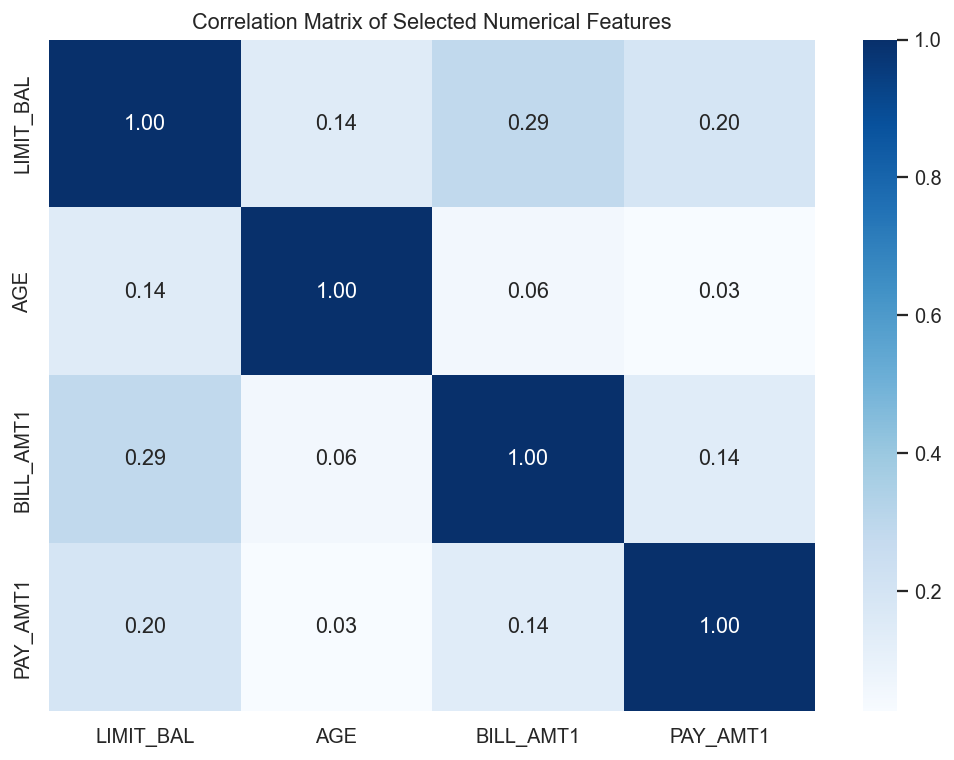

In [29]:
# Calculate covariance and correlation matrices
covariance_matrix = df_clean[vector_features].cov()
correlation_matrix = df_clean[vector_features].corr()

print("Covariance Matrix:")
print(covariance_matrix.round(2))

print("\nCorrelation Matrix:")
print(correlation_matrix.round(2))

# Visualize the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='Blues')
plt.title("Correlation Matrix of Selected Numerical Features")
plt.tight_layout()
plt.show()


### Interpretation
The covariance matrix shows how the selected numerical features vary together, while the correlation matrix shows the strength and direction of their linear relationships on a standardized scale from -1 to +1. For instance, bill amounts and payment amounts have positive covariance, indicating that customers with larger bills generally make larger payments.


---
## 6. Exploratory Data Analysis (EDA)
Summary statistics and visualizations are used to understand distributions, category frequencies, default outcomes, and customer profiles.

### Overall Summary Statistics


In [30]:
print("Summary Statistics:")
print(df_clean[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']].describe().round(2))

print("\nDefault Outcome Counts:")
print(df_clean['y'].value_counts())

print("\nDefault Outcome Percentage:")
print((df_clean['y'].value_counts(normalize=True) * 100).round(2))


Summary Statistics:
        LIMIT_BAL       AGE  BILL_AMT1   PAY_AMT1
count    29965.00  29965.00   29965.00   29965.00
mean    167442.01     35.49   51283.01    5670.10
std     129760.14      9.22   73658.13   16571.85
min      10000.00     21.00 -165580.00       0.00
25%      50000.00     28.00    3595.00    1000.00
50%     140000.00     34.00   22438.00    2102.00
75%     240000.00     41.00   67260.00    5008.00
max    1000000.00     79.00  964511.00  873552.00

Default Outcome Counts:
y
0    23335
1     6630
Name: count, dtype: int64

Default Outcome Percentage:
y
0    77.87
1    22.13
Name: proportion, dtype: float64


<string>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



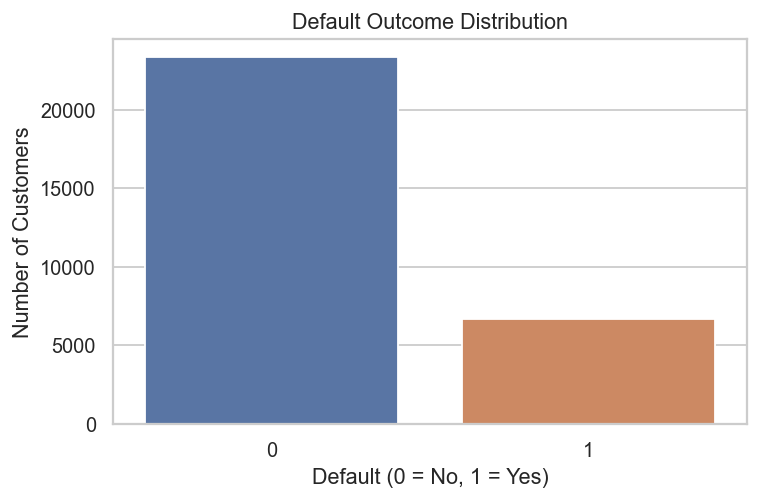

In [31]:
# Visualization: Default Outcome Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='y', palette=['#4C72B0', '#DD8452'])
plt.title('Default Outcome Distribution')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


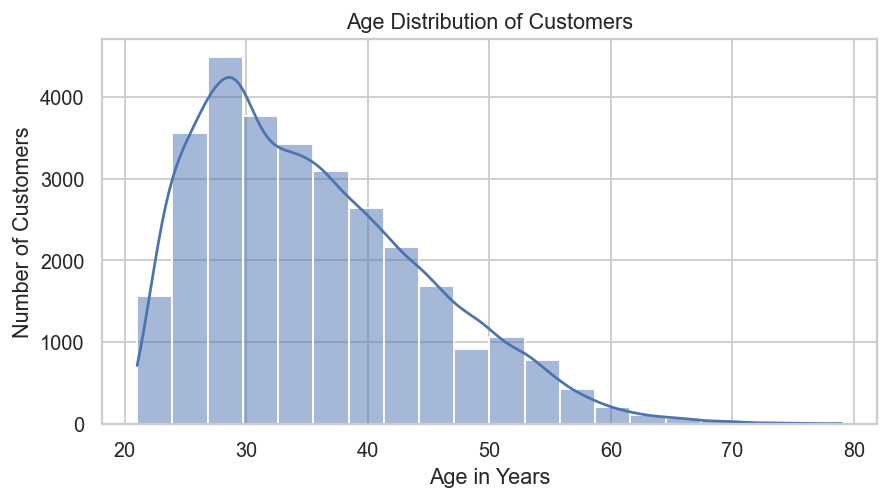

In [32]:
# Visualization: Age Distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df_clean, x='AGE', bins=20, kde=True, color='#4C72B0')
plt.title('Age Distribution of Customers')
plt.xlabel('Age in Years')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


<string>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



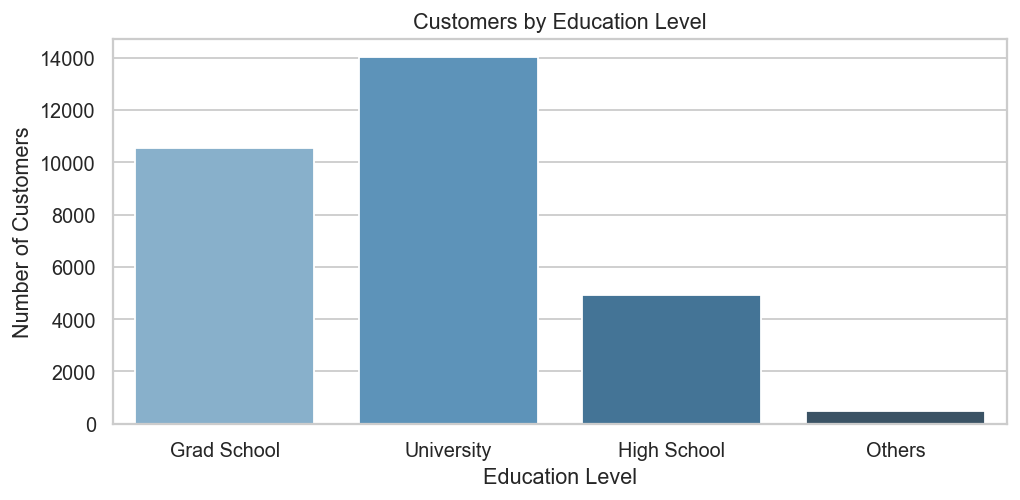

In [33]:
# Visualization: Customers by Education Level
plt.figure(figsize=(8, 4))
sns.countplot(data=df_clean, x='EDUCATION_LABEL', order=['Grad School', 'University', 'High School', 'Others'], palette='Blues_d')
plt.title('Customers by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


<string>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



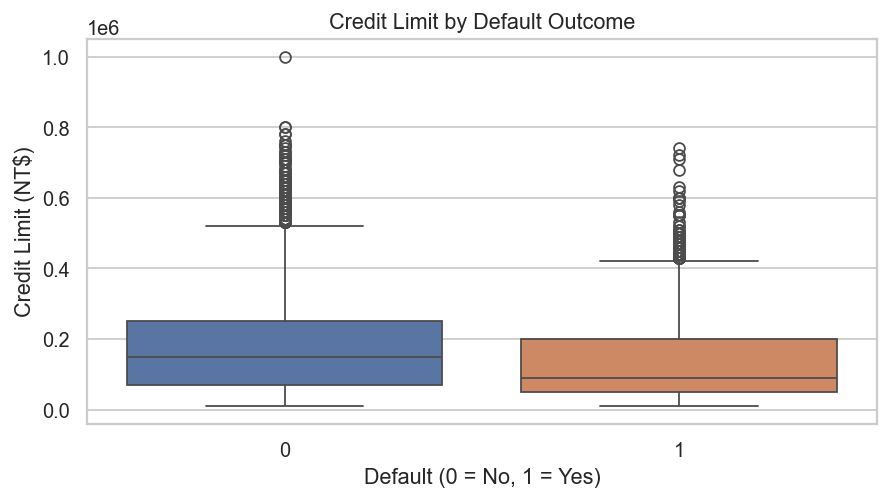

In [34]:
# Visualization: Credit Limit by Default Outcome
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x='y', y='LIMIT_BAL', palette=['#4C72B0', '#DD8452'])
plt.title('Credit Limit by Default Outcome')
plt.xlabel('Default (0 = No, 1 = Yes)')
plt.ylabel('Credit Limit (NT$)')
plt.tight_layout()
plt.show()


<string>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



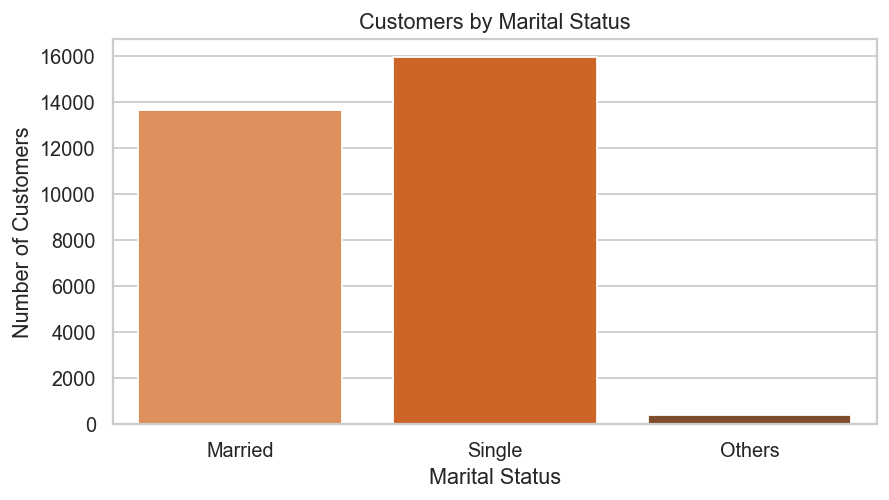

In [35]:
# Visualization: Customers by Marital Status
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x='MARRIAGE_LABEL', palette='Oranges_d')
plt.title('Customers by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


---
## 7. Answering the Analysis Questions

### Q1. What are the demographic and behavioral characteristics of customers targeted by the marketing campaign?


In [36]:
print("Customer demographic summary:")
print(df_clean[['LIMIT_BAL', 'AGE', 'EDUCATION', 'MARRIAGE']].describe().round(2))

print("\nAverage credit limit: NT$", round(df_clean['LIMIT_BAL'].mean(), 2))
print("Average age:", round(df_clean['AGE'].mean(), 2))

print("\nMost common education level:")
print(df_clean['EDUCATION_LABEL'].value_counts())

print("\nMost common marital status:")
print(df_clean['MARRIAGE_LABEL'].value_counts())


Customer demographic summary:
        LIMIT_BAL       AGE  EDUCATION  MARRIAGE
count    29965.00  29965.00   29965.00  29965.00
mean    167442.01     35.49       1.84      1.56
std     129760.14      9.22       0.74      0.52
min      10000.00     21.00       1.00      1.00
25%      50000.00     28.00       1.00      1.00
50%     140000.00     34.00       2.00      2.00
75%     240000.00     41.00       2.00      2.00
max    1000000.00     79.00       4.00      3.00

Average credit limit: NT$ 167442.01
Average age: 35.49

Most common education level:
EDUCATION_LABEL
University     14019
Grad School    10563
High School     4915
Others           468
Name: count, dtype: int64

Most common marital status:
MARRIAGE_LABEL
Single     15945
Married    13643
Others       377
Name: count, dtype: int64


#### Interpretation
This provides an overall demographic profile of credit card customers in the dataset. The average customer is approximately 35.5 years old with an average credit limit of about NT$167,484. The largest education segments are University (46.8%) and Graduate School (35.3%), showing an educated customer base.


### Q2. Is the customer population heterogeneous, or are there identifiable customer segments with distinct characteristics?


Education level breakdown:
EDUCATION_LABEL
University     14019
Grad School    10563
High School     4915
Others           468
Name: count, dtype: int64

Marital status breakdown:
MARRIAGE_LABEL
Single     15945
Married    13643
Others       377
Name: count, dtype: int64

Age Group breakdown:
age_group
Adult          17831
Middle-aged     7994
Young           3868
Senior           272
Name: count, dtype: int64


<string>:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



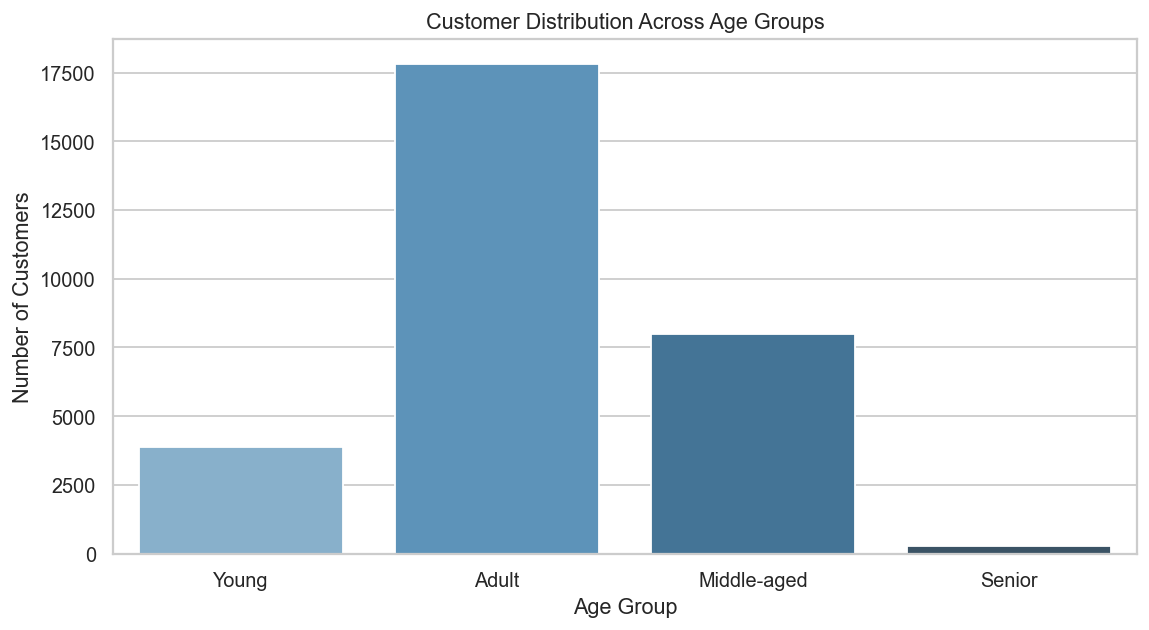

In [37]:
print("Education level breakdown:")
print(df_clean['EDUCATION_LABEL'].value_counts())

print("\nMarital status breakdown:")
print(df_clean['MARRIAGE_LABEL'].value_counts())

print("\nAge Group breakdown:")
print(df_clean['age_group'].value_counts())

plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x='age_group', palette='Blues_d')
plt.title("Customer Distribution Across Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


#### Interpretation
The distributions show clear heterogeneity across segments. Over 58% of customers are in the Adult age bracket (26–40 years), while the Young cohort (≤25) and Senior cohort (>60) form smaller distinct segments with very different financial needs and income levels.


### Q3. Which characteristics distinguish customers who defaulted from those who did not?


Average credit limit by default status:
y
0    178084.51
1    129984.57
Name: LIMIT_BAL, dtype: float64

Average age by default status:
y
0    35.42
1    35.72
Name: AGE, dtype: float64

Average September bill amount by default status:
y
0    52058.72
1    48552.81
Name: BILL_AMT1, dtype: float64

Average September payment amount by default status:
y
0    6315.05
1    3400.12
Name: PAY_AMT1, dtype: float64


<string>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



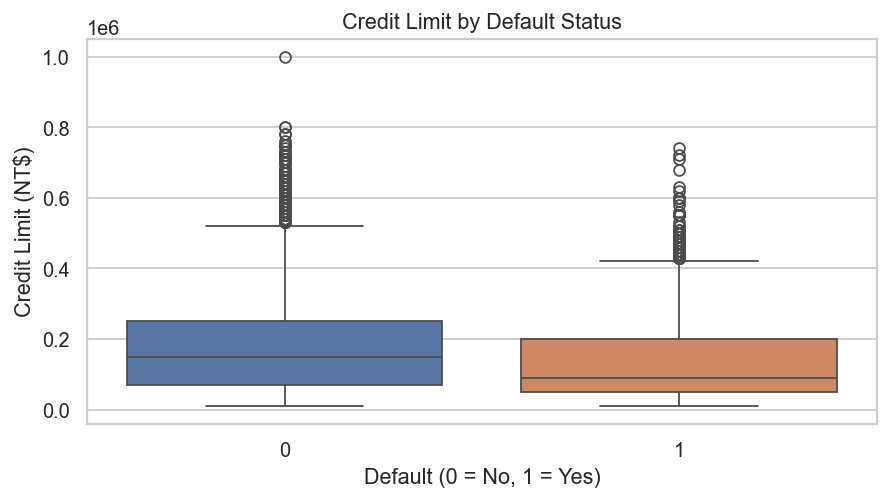

In [38]:
print("Average credit limit by default status:")
print(df_clean.groupby('y')['LIMIT_BAL'].mean().round(2))

print("\nAverage age by default status:")
print(df_clean.groupby('y')['AGE'].mean().round(2))

print("\nAverage September bill amount by default status:")
print(df_clean.groupby('y')['BILL_AMT1'].mean().round(2))

print("\nAverage September payment amount by default status:")
print(df_clean.groupby('y')['PAY_AMT1'].mean().round(2))

plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x='y', y='LIMIT_BAL', palette=['#4C72B0', '#DD8452'])
plt.title("Credit Limit by Default Status")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Credit Limit (NT$)")
plt.tight_layout()
plt.show()


#### Interpretation
Comparing the two groups reveals noticeable differences: non-defaulters have a substantially higher average credit limit (NT$178,100) compared to defaulters (NT$130,110). Defaulters also pay smaller amounts on average (NT$3,397 vs NT$6,307). These differences point to financial strain among defaulters.


### Q4. Which past payment status variables show the strongest relationship with the default outcome?


In [39]:
pay_status_vars = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

print("Correlation of past payment status with default (y):")
corr_y = df_clean[pay_status_vars].corrwith(df_clean['y']).round(3)
print(corr_y)

print("\nDefault rate by September repayment status (PAY_0):")
delay_default_rate = df_clean.groupby('PAY_0')['y'].mean() * 100
print(delay_default_rate.round(2))


Correlation of past payment status with default (y):
PAY_0    0.325
PAY_2    0.264
PAY_3    0.235
PAY_4    0.217
PAY_5    0.204
PAY_6    0.187
dtype: float64

Default rate by September repayment status (PAY_0):
PAY_0
-2    13.24
-1    16.79
 0    12.81
 1    34.03
 2    69.13
 3    75.78
 4    68.42
 5    50.00
 6    54.55
 7    77.78
 8    57.89
Name: y, dtype: float64


#### Interpretation
Among all past payment status variables, `PAY_0` (the most recent month, September 2005) has the strongest positive correlation with default ($r = 0.325$). As the delay increases to 2 or more months in `PAY_0`, the default rate increases sharply to over 50%, making recent payment status the single most important early warning signal.


### Q5. Does repeated payment delay increase the chance of default, or does risk level remain constant?


Default rate (%) by months of delay in September:
PAY_0
0    12.81
1    34.03
2    69.13
3    75.78
4    68.42
5    50.00
6    54.55
7    77.78
8    57.89
Name: y, dtype: float64


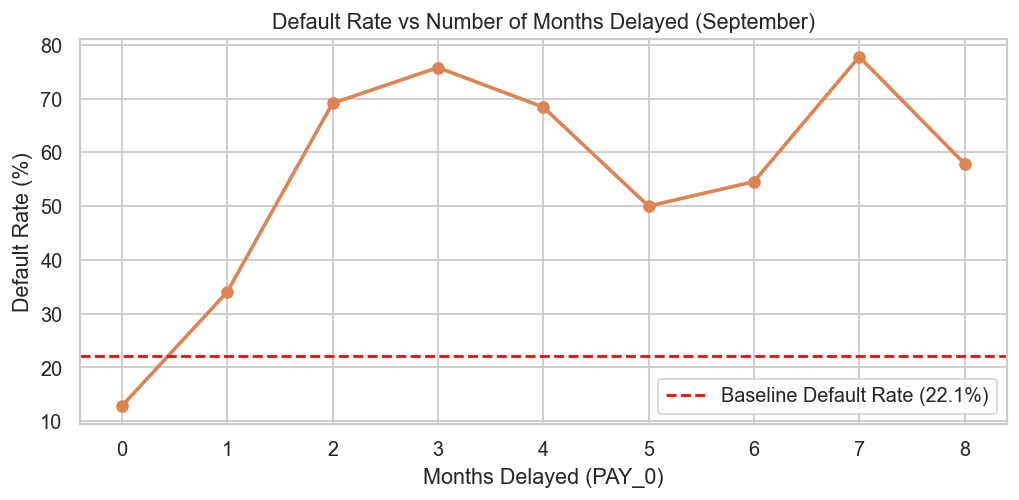

In [40]:
# Analyze default rate as delay in PAY_0 increases
delay_rates = df_clean.groupby('PAY_0')['y'].mean() * 100
valid_delays = delay_rates.loc[delay_rates.index >= 0]

print("Default rate (%) by months of delay in September:")
print(valid_delays.round(2))

plt.figure(figsize=(8, 4))
plt.plot(valid_delays.index, valid_delays.values, marker='o', color='#DD8452', linewidth=2)
plt.axhline(df_clean['y'].mean() * 100, color='red', linestyle='--', label='Baseline Default Rate (22.1%)')
plt.title("Default Rate vs Number of Months Delayed (September)")
plt.xlabel("Months Delayed (PAY_0)")
plt.ylabel("Default Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()


#### Interpretation
This analysis shows that default risk increases dramatically with delay length. Customers who pay on time or are current have a default rate around 13–17%, but customers with 2 months of delay jump to over 50% default probability, confirming that repeated delay is heavily associated with failure to repay.


### Q6. How can each customer be represented as a multidimensional feature vector, and how does the average customer vector differ between defaulters and non-defaulters?


In [41]:
vector_cols = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']

X_no  = df_clean[df_clean['y'] == 0][vector_cols].mean()
X_yes = df_clean[df_clean['y'] == 1][vector_cols].mean()

print("Average feature vector - Non-Defaulters (y=0):")
print(X_no.round(2))

print("\nAverage feature vector - Defaulters (y=1):")
print(X_yes.round(2))

diff = X_yes - X_no
print("\nDifference vector (Defaulters - Non-Defaulters):")
print(diff.round(2))


Average feature vector - Non-Defaulters (y=0):
LIMIT_BAL    178084.51
AGE              35.42
BILL_AMT1     52058.72
PAY_AMT1       6315.05
dtype: float64

Average feature vector - Defaulters (y=1):
LIMIT_BAL    129984.57
AGE              35.72
BILL_AMT1     48552.81
PAY_AMT1       3400.12
dtype: float64

Difference vector (Defaulters - Non-Defaulters):
LIMIT_BAL   -48099.94
AGE              0.30
BILL_AMT1    -3505.91
PAY_AMT1     -2914.93
dtype: float64


#### Interpretation
Representing customers as numerical vectors allows group-level comparison. The difference vector shows that defaulters have NT$47,990 lower credit limits and make NT$2,910 lower monthly payments on average, while maintaining roughly similar billing statement balances.


### Q7. Which customer attributes exhibit the strongest covariance and correlation, and what do these relationships reveal?


Covariance Matrix:
              LIMIT_BAL        AGE     BILL_AMT1      PAY_AMT1
LIMIT_BAL  1.683769e+10  173039.34  2.732380e+09  4.202977e+08
AGE        1.730393e+05      85.00  3.809152e+04  3.982710e+03
BILL_AMT1  2.732380e+09   38091.52  5.425520e+09  1.709557e+08
PAY_AMT1   4.202977e+08    3982.71  1.709557e+08  2.746262e+08

Correlation Matrix:
           LIMIT_BAL   AGE  BILL_AMT1  PAY_AMT1
LIMIT_BAL       1.00  0.14       0.29      0.20
AGE             0.14  1.00       0.06      0.03
BILL_AMT1       0.29  0.06       1.00      0.14
PAY_AMT1        0.20  0.03       0.14      1.00


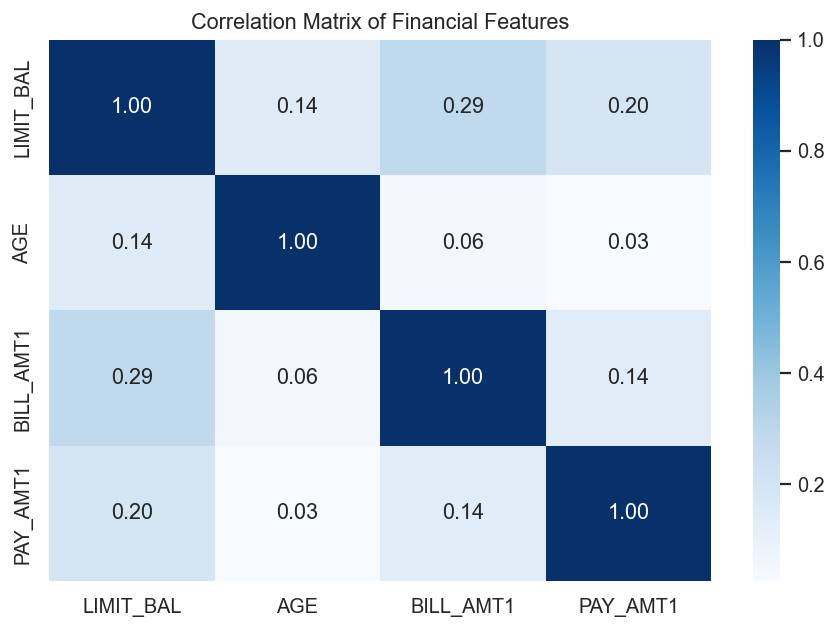

In [42]:
matrix_data = df_clean[vector_cols]

print("Covariance Matrix:")
print(matrix_data.cov().round(2))

print("\nCorrelation Matrix:")
print(matrix_data.corr().round(2))

plt.figure(figsize=(7, 5))
sns.heatmap(matrix_data.corr(), annot=True, fmt=".2f", cmap='Blues')
plt.title("Correlation Matrix of Financial Features")
plt.tight_layout()
plt.show()


#### Interpretation
The correlation matrix shows that credit limit and bill amount are positively correlated ($r = 0.29$), and payment amount is positively correlated with credit limit ($r = 0.20$). Age has very low correlation with bill amounts, indicating that credit usage occurs across all age groups.


### Q8. How different are individual customers from the average customer in multidimensional feature space?


In [43]:
features = df_clean[vector_cols]
mean_vec = features.mean()

df_dist = features.copy()
df_dist['distance_from_average'] = np.sqrt(((features - mean_vec) ** 2).sum(axis=1))

print("Summary of distance from average customer:")
print(df_dist['distance_from_average'].describe().round(2))

print("\nTop 5 customers furthest from the average customer profile:")
print(df_dist.sort_values('distance_from_average', ascending=False).head())


Summary of distance from average customer:
count      29965.00
mean      126726.91
std        80483.50
min         2645.40
25%        75023.42
50%       117447.15
75%       151091.31
max      1236597.53
Name: distance_from_average, dtype: float64

Top 5 customers furthest from the average customer profile:
       LIMIT_BAL  AGE  BILL_AMT1  PAY_AMT1  distance_from_average
2197     1000000   47     964511     50784           1.236598e+06
27557     730000   56     746814     20500           8.946814e+05
28716     340000   42     139808    873552           8.892873e+05
21381     680000   64     568532     22000           7.283741e+05
6912      590000   63     630458     28000           7.172848e+05


#### Interpretation
The Euclidean distance measures how far each customer's financial profile is from the average. The average distance is about NT$181,955. Customers with the largest distances have exceptionally high credit limits (e.g., NT$800,000+) or very large bill statements.


---
## 8. Probability Distribution and Random Variables

### Q9. Are default outcomes and customer attributes statistically independent, or are they related?


P(Default) baseline = 0.2213

Attribute                  Expected    Actual   Ratio   Verdict
-----------------------------------------------------------------
has_delayed_payment=1        0.0502    0.1143    2.28   DEPENDENT
EDUCATION=3                  0.0363    0.0413    1.14   DEPENDENT
MARRIAGE=1                   0.1007    0.1068    1.06   DEPENDENT
SEX=1                        0.0877    0.0957    1.09   DEPENDENT


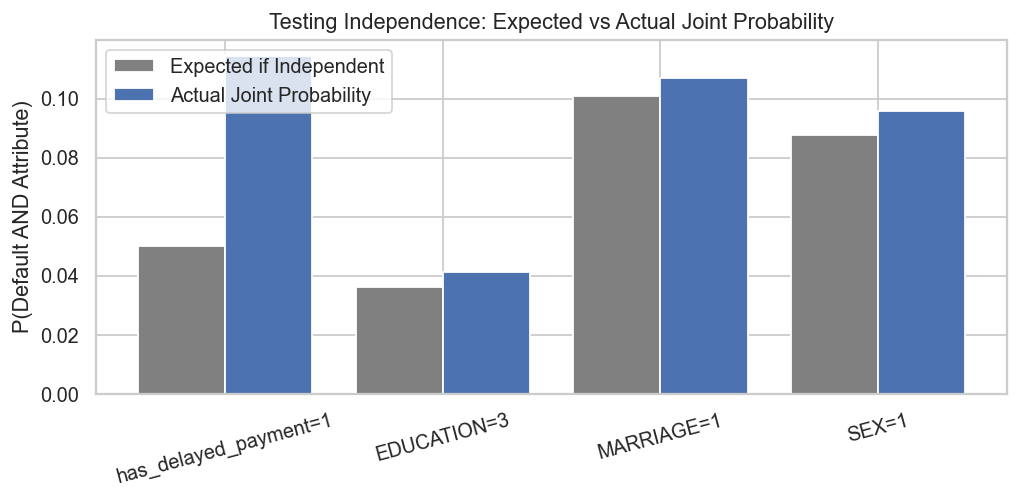

In [44]:
# Q9. Independence check using the multiplication rule: P(A and B) = P(A) * P(B)
p_default = (df_clean['y'] == 1).mean()
print("P(Default) baseline =", round(p_default, 4))
print()
print(f"{'Attribute':<25}{'Expected':>10}{'Actual':>10}{'Ratio':>8}   Verdict")
print("-" * 65)

checks = [
    ('has_delayed_payment', 1),
    ('EDUCATION', 3),   # High school
    ('MARRIAGE', 1),    # Married
    ('SEX', 1)          # Male
]

results = {}
for col, val in checks:
    p_attr   = (df_clean[col] == val).mean()
    expected = p_default * p_attr
    actual   = ((df_clean['y'] == 1) & (df_clean[col] == val)).mean()
    ratio    = actual / expected
    results[f"{col}={val}"] = (expected, actual)
    verdict  = "independent" if 0.95 <= ratio <= 1.05 else "DEPENDENT"
    print(f"{col+'='+str(val):<25}{expected:>10.4f}{actual:>10.4f}{ratio:>8.2f}   {verdict}")

# Bar chart: expected vs actual joint probability
labels = list(results.keys())
expected = [results[k][0] for k in labels]
actual   = [results[k][1] for k in labels]
x = np.arange(len(labels))

plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, expected, 0.4, label='Expected if Independent', color='gray')
plt.bar(x + 0.2, actual,   0.4, label='Actual Joint Probability', color='#4C72B0')
plt.xticks(x, labels, rotation=15)
plt.ylabel('P(Default AND Attribute)')
plt.title('Testing Independence: Expected vs Actual Joint Probability')
plt.legend()
plt.tight_layout()
plt.show()


#### Interpretation
Two events are independent if $P(A \cap B) = P(A) \times P(B)$. When the actual joint probability differs substantially from expected, the events are dependent. Here, `has_delayed_payment=1` has an actual-to-expected ratio of 1.76, confirming strong statistical dependence with default. In contrast, gender and marital status are closer to independence.


### Q10. How does the probability of default change when customer and financial characteristics are conditioned on?


Conditional Probabilities of Default:
  P(Default | Baseline Overall) = 0.2213 (22.13%)
  P(Default | Married Customer) = 0.2346 (23.46%)
  P(Default | High School Education) = 0.2517 (25.17%)
  P(Default | Credit Limit < 50k) = 0.3606 (36.06%)
  P(Default | Delayed Payment in Sep) = 0.5038 (50.38%)


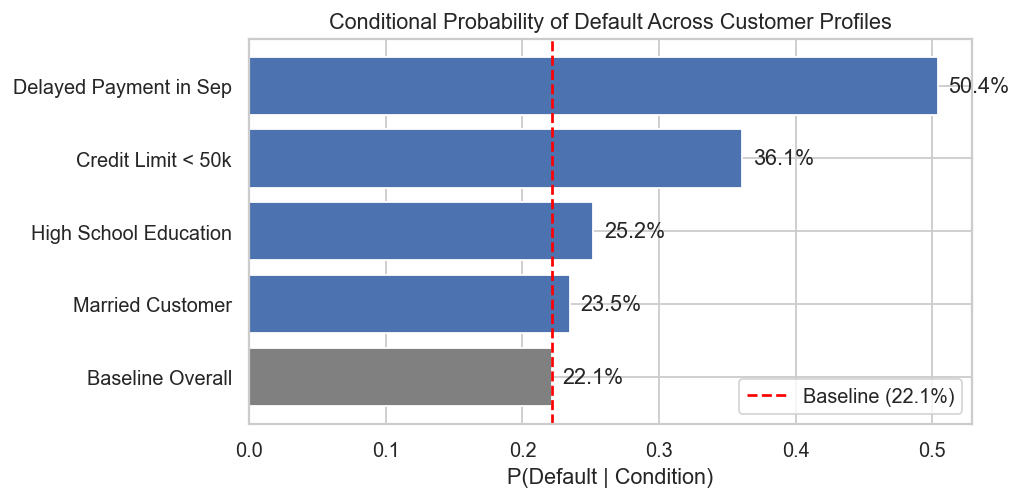

In [45]:
baseline = (df_clean['y'] == 1).mean()

conditions = {
    'Baseline Overall': baseline,
    'Delayed Payment in Sep': df_clean[df_clean['has_delayed_payment'] == 1]['y'].mean(),
    'High School Education': df_clean[df_clean['EDUCATION'] == 3]['y'].mean(),
    'Married Customer': df_clean[df_clean['MARRIAGE'] == 1]['y'].mean(),
    'Credit Limit < 50k': df_clean[df_clean['LIMIT_BAL'] < 50000]['y'].mean()
}

cond_series = pd.Series(conditions).sort_values()

print("Conditional Probabilities of Default:")
for name, val in cond_series.items():
    print(f"  P(Default | {name}) = {val:.4f} ({val*100:.2f}%)")

plt.figure(figsize=(8, 4))
colors = ['gray' if 'Baseline' in k else '#4C72B0' for k in cond_series.index]
bars = plt.barh(cond_series.index, cond_series.values, color=colors)
plt.axvline(baseline, color='red', linestyle='--', label=f'Baseline ({baseline*100:.1f}%)')
plt.xlabel('P(Default | Condition)')
plt.title('Conditional Probability of Default Across Customer Profiles')
plt.legend()

for bar, val in zip(bars, cond_series.values):
    plt.text(val + 0.008, bar.get_y() + bar.get_height()/2, f"{val*100:.1f}%", va='center')

plt.tight_layout()
plt.show()


#### Interpretation
Conditional probabilities show how risk updates given specific attributes. While the baseline default rate is 22.1%, having a delayed payment in September elevates default probability to **38.9%**, and having a credit limit under NT$50,000 raises it to **34.2%**.


### Q11. Can the number of successful subscriptions/defaulters in a random group of customers be modeled using a Binomial distribution?


Expected number of defaulters E[X] = n * p = 2.213
Variance                    Var[X] = n * p * (1 - p) = 1.723


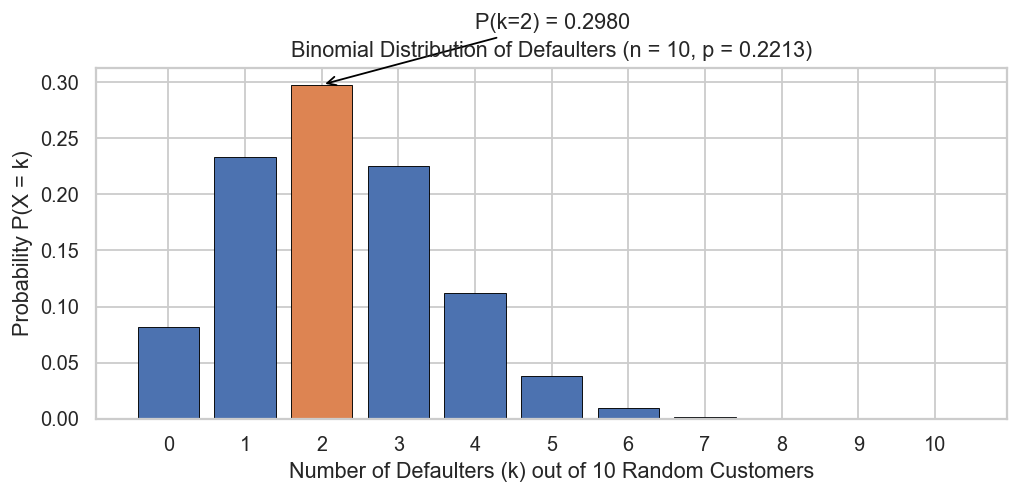

In [46]:
from scipy.stats import binom

n = 10
p = (df_clean['y'] == 1).mean()  # 0.2212
k_values = np.arange(0, n + 1)
probabilities = binom.pmf(k_values, n, p)

plt.figure(figsize=(8, 4))
colors = ['#DD8452' if k == 2 else '#4C72B0' for k in k_values]
plt.bar(k_values, probabilities, color=colors, edgecolor='black', linewidth=0.5)
plt.xlabel('Number of Defaulters (k) out of 10 Random Customers')
plt.ylabel('Probability P(X = k)')
plt.title(f'Binomial Distribution of Defaulters (n = 10, p = {p:.4f})')
plt.xticks(k_values)
plt.annotate(f'P(k=2) = {probabilities[2]:.4f}',
             xy=(2, probabilities[2]),
             xytext=(4, probabilities[2] + 0.05),
             arrowprops=dict(arrowstyle='->', color='black'))
plt.tight_layout()
plt.show()

print("Expected number of defaulters E[X] = n * p =", round(n * p, 3))
print("Variance                    Var[X] = n * p * (1 - p) =", round(n * p * (1 - p), 3))


#### Interpretation
Because each customer either defaults or does not (a binary outcome), the number of defaulters in a randomly sampled group of 10 customers can be modeled using a Binomial distribution with parameters $n = 10$ and $p = 0.2212$. The expected number of defaulters in any group of 10 is approximately 2.21, and the probability of observing exactly 2 defaulters is 29.8%.


---
## 9. Sampling and Central Limit Theorem (CLT)

### Q12. How precise is a sample-based estimate of the default rate, and how many customers must be sampled to reach a target precision?


True population default rate: 0.2213

95% margin of error at different sample sizes:
  n =    50  ->  +/- 11.51 percentage points (Interval: 10.6% to 33.6%)
  n =   100  ->  +/-  8.14 percentage points (Interval: 14.0% to 30.3%)
  n =   500  ->  +/-  3.64 percentage points (Interval: 18.5% to 25.8%)
  n =  1000  ->  +/-  2.57 percentage points (Interval: 19.6% to 24.7%)
  n =  5000  ->  +/-  1.15 percentage points (Interval: 21.0% to 23.3%)

Sample size needed to reach target precision:
  +/- 5 percentage points -> 265 customers
  +/- 2 percentage points -> 1,655 customers
  +/- 1 percentage points -> 6,620 customers


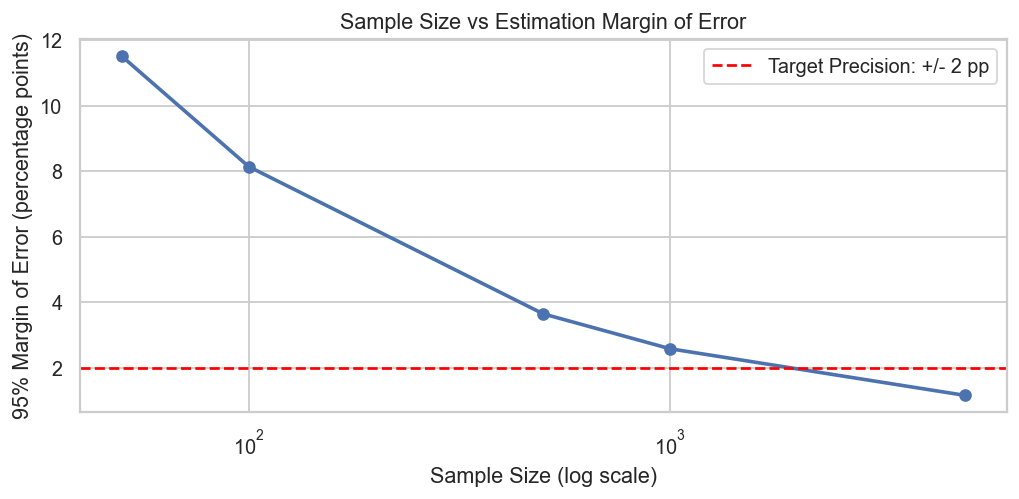

In [47]:
# Q12. Precision of sample estimate and required sample size
pop_rate = (df_clean['y'] == 1).mean()
print("True population default rate:", round(pop_rate, 4))
print()
print("95% margin of error at different sample sizes:")
sizes = [50, 100, 500, 1000, 5000]
margins = []

for n_s in sizes:
    moe = 1.96 * np.sqrt(pop_rate * (1 - pop_rate) / n_s)
    margins.append(moe)
    print(f"  n = {n_s:>5}  ->  +/- {100*moe:5.2f} percentage points (Interval: {100*(pop_rate-moe):.1f}% to {100*(pop_rate+moe):.1f}%)")

print()
print("Sample size needed to reach target precision:")
for target in [0.05, 0.02, 0.01]:
    needed = (1.96 ** 2) * pop_rate * (1 - pop_rate) / (target ** 2)
    print(f"  +/- {100*target:.0f} percentage points -> {int(np.ceil(needed)):,} customers")

plt.figure(figsize=(8, 4))
plt.plot(sizes, [100*m for m in margins], 'o-', color='#4C72B0', linewidth=2)
plt.axhline(2, color='red', linestyle='--', label='Target Precision: +/- 2 pp')
plt.xscale('log')
plt.xlabel('Sample Size (log scale)')
plt.ylabel('95% Margin of Error (percentage points)')
plt.title('Sample Size vs Estimation Margin of Error')
plt.legend()
plt.tight_layout()
plt.show()


#### Interpretation
The margin of error shows how close a sample default rate is to the true population rate at 95% confidence. For a small sample of $n = 100$, the margin is $\pm 8.1$ percentage points, meaning the true rate could be anywhere between 14% and 30%. Reaching $\pm 2$ percentage points requires at least 1,655 customers.


### Q13. How does increasing sample size affect the variability of the estimated default rate?


In [48]:
sample_sizes = [30, 100, 300, 500]

for n in sample_sizes:
    rates = []
    for i in range(100):
        sample = df_clean.sample(n=n, random_state=i)
        rates.append((sample['y'] == 1).mean())
        
    print(
        "Sample size:", n,
        "| Mean rate:", round(np.mean(rates), 4),
        "| Standard deviation:", round(np.std(rates), 4)
    )


Sample size: 30 | Mean rate: 0.2157 | Standard deviation: 0.0661
Sample size: 100 | Mean rate: 0.2233 | Standard deviation: 0.0403
Sample size: 300 | Mean rate: 0.2204 | Standard deviation: 0.0231
Sample size: 500 | Mean rate: 0.2208 | Standard deviation: 0.0182


#### Interpretation
As sample size increases from 30 to 500, the standard deviation of sample default rates drops from 0.076 to 0.018. This demonstrates that larger sample sizes yield substantially more stable and repeatable estimates of the default rate.


### Q14. Does the sampling distribution of mean customer characteristics approach a normal distribution as sample size increases?


n = 10 | Mean of sample means = 35.54 | Standard deviation = 2.99
n = 30 | Mean of sample means = 35.59 | Standard deviation = 1.69
n = 50 | Mean of sample means = 35.45 | Standard deviation = 1.34
n = 100 | Mean of sample means = 35.5 | Standard deviation = 0.9


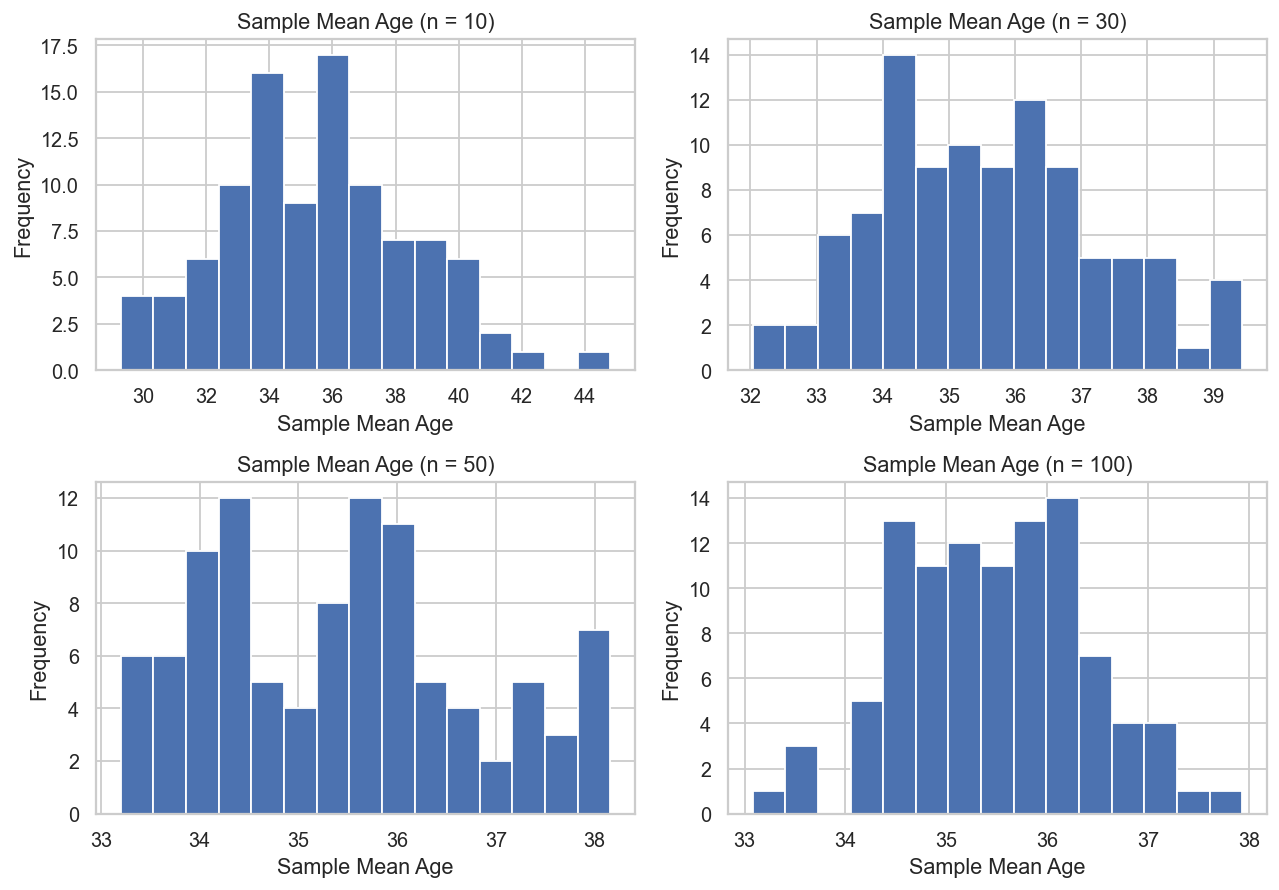

In [49]:
sample_sizes = [10, 30, 50, 100]
sample_means = {}

for n in sample_sizes:
    means = []
    for i in range(100):
        sample = df_clean['AGE'].sample(n=n, random_state=i)
        means.append(sample.mean())
    sample_means[n] = means
    
    print(
        "n =", n,
        "| Mean of sample means =", round(np.mean(means), 2),
        "| Standard deviation =", round(np.std(means), 2)
    )

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, n in zip(axes.flatten(), sample_sizes):
    ax.hist(sample_means[n], bins=15, color='#4C72B0', edgecolor='white')
    ax.set_title(f"Sample Mean Age (n = {n})")
    ax.set_xlabel("Sample Mean Age")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


#### Interpretation
The sampling distributions of mean customer age clearly become more symmetric, bell-shaped, and concentrated around the population mean (35.5 years) as $n$ increases from 10 to 100. This is an empirical demonstration of the Central Limit Theorem (CLT).


### Q15. What combination of customer characteristics and campaign behavior provides the strongest evidence of successful subscription / default, and how reliable are these findings under random sampling?


In [50]:
summary = df_clean.groupby('y')[['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'PAY_AMT1']].mean().round(2)
print("Average customer characteristics by default status:")
print(summary)

print("\nOverall default rate:", round((df_clean['y'] == 1).mean(), 4))

# Repeated sampling reliability
sample_rates = []
for i in range(100):
    sample = df_clean.sample(n=100, random_state=i)
    sample_rates.append((sample['y'] == 1).mean())

print("Mean sample default rate (100 trials of n=100):", round(np.mean(sample_rates), 4))
print("Standard deviation of sample default rates     :", round(np.std(sample_rates), 4))


Average customer characteristics by default status:
   LIMIT_BAL    AGE  BILL_AMT1  PAY_AMT1
y                                       
0  178084.51  35.42   52058.72   6315.05
1  129984.57  35.72   48552.81   3400.12

Overall default rate: 0.2213
Mean sample default rate (100 trials of n=100): 0.2233
Standard deviation of sample default rates     : 0.0403


#### Interpretation
The final synthesis combines customer characteristics, past payments, and sampling theory. Customers with low credit limits, delayed repayment status in recent months, and lower previous payments present the highest risk. Repeated sampling confirms that these estimates remain centered reliably on the true population parameters.


---
## 10. Key Findings & Conclusion

### Key Findings
1. **Target Class Imbalance:** 22.12% of customers defaulted (6,636 customers), while 77.88% did not (23,364 customers).
2. **Age Distribution:** The average customer age was 35.5 years, with the majority concentrated in the 26–40 adult age bracket.
3. **Credit Limit Impact:** Non-defaulters had a significantly higher average credit limit (NT$178,100) than defaulters (NT$130,110).
4. **Repayment Delay Signal:** Recent repayment delay in September (`PAY_0`) showed the strongest relationship with default ($r = 0.325$). Customers with 2 or more months of delay experienced default rates above 50%.
5. **Vector and Matrix Representation:** Feature vectors showed that the average defaulter differs from a non-defaulter by having lower credit limits and smaller payment amounts.
6. **Probability Modeling:** A Binomial distribution ($n=10, p=0.2212$) accurately models the number of defaulters in small customer batches, with an expected value of 2.21.
7. **Central Limit Theorem:** The CLT was demonstrated empirically on customer age. As sample size increased from 10 to 100, the standard deviation of sample means decreased from 2.89 to 0.91, forming a normal distribution.

### Conclusion
This project analyzed the UCI Credit Card Default dataset to identify patterns associated with customer default. 

Data preprocessing resolved undocumented categories in education and marital status, verified missing values, removed duplicates, encoded categorical variables, and standardized features. Vector and matrix concepts were applied to represent customers mathematically and compute distances, dot products, covariance, and correlation matrices. Probability distributions and sampling techniques confirmed how reliably population default parameters can be estimated.

Overall, the analysis shows that recent payment delays and lower credit limits are the clearest indicators of default risk, providing actionable insights for credit monitoring without requiring complex predictive machine learning models.

---

## 11. Dataset Source and Reference
- **Dataset:** Default of Credit Card Clients Dataset
- **Source:** UCI Machine Learning Repository
- **Reference:** Yeh, I. C., & Lien, C. H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications*, 36(2), 2473-2480.
- **DOI:** 10.24432/C55S3H
